In [2]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

data_dir = Path.cwd()

print(list(data_dir.glob("*.jsonl.gz")))

[PosixPath('/Users/emmagurevich/Desktop/Data 144/FinalProject/Health_and_Household.jsonl.gz'), PosixPath('/Users/emmagurevich/Desktop/Data 144/FinalProject/meta_Health_and_Household.jsonl.gz'), PosixPath('/Users/emmagurevich/Desktop/Data 144/FinalProject/meta_All_Beauty.jsonl.gz'), PosixPath('/Users/emmagurevich/Desktop/Data 144/FinalProject/All_Beauty.jsonl.gz')]


## EDA
Investigate which category will lead to a more insightful modeling results:
* Beauty

* Health and Household (more specifically, one distinct category within Health and Household, i.e. Cleaning Supplies)

### File Structures and Information:
* Review files: 
    * One row per review
    * Review Text
    * Star Rating
    * Reviewer ID 
    * Review Date
* Metadata files: 
    * One row per product record 
    * Product name
    * Product description 
    * Product brand 
    * Product price
    * Product categories

In [4]:
# Load in Beauty Category Data
beauty_reviews = pd.read_json(data_dir / "All_Beauty.jsonl.gz", lines=True)
beauty_meta = pd.read_json(data_dir / "meta_All_Beauty.jsonl.gz", lines=True)

In [5]:
# Load in Household and Health Category Data
household_meta = pd.read_json(data_dir / "meta_Health_and_Household.jsonl.gz", lines=True)

# The Household and Health category data contains about 25.6 million rows, so the dataframe will 
# be composed up of 128,000 randomly sampled rows
household_reviews = pd.read_json(data_dir / "Health_and_Household.jsonl.gz", lines=True, nrows=128000)

In [6]:
# Save household dataframe locally
household_reviews.to_pickle("household_sample.pkl")

### Inspect the Dataframes and Summary Statistics 

In [7]:
beauty_reviews.describe()

,rating,timestamp,helpful_vote
count,701528.000000,701528,701528.000000
mean,3.960245,2019-04-09 03:31:48.115045,0.923588
min,1.000000,2000-11-01 04:24:18,0.000000
25%,3.000000,2017-08-01 19:39:25.777500,0.000000
50%,5.000000,2019-10-20 18:11:28.616500,0.000000
75%,5.000000,2021-03-02 01:05:05.558000,1.000000
max,5.000000,2023-09-09 00:39:36.666000,646.000000
std,1.494452,NaN,5.471391


In [8]:
beauty_meta.describe()

,average_rating,rating_number,price,bought_together
count,112590.000000,112590.000000,17704.00000,0.0
mean,3.883488,50.541345,27.25573,NaN
std,0.874384,310.992502,50.47202,NaN
min,1.000000,1.000000,0.01000,NaN
25%,3.400000,3.000000,9.99000,NaN
50%,4.000000,9.000000,16.99000,NaN
75%,4.500000,28.000000,29.90000,NaN
max,5.000000,30206.000000,2548.98000,NaN


In [9]:
household_reviews.describe()

,rating,timestamp,helpful_vote
count,128000.000000,128000,128000.000000
mean,4.304719,2019-08-15 06:34:44.395849,1.707484
min,1.000000,2001-07-17 22:59:19,0.000000
25%,4.000000,2018-02-28 21:33:54.788500,0.000000
50%,5.000000,2020-01-13 10:32:04.581000,0.000000
75%,5.000000,2021-07-08 04:27:12.738000,1.000000
max,5.000000,2023-03-17 08:13:45.216000,1524.000000
std,1.169095,NaN,16.711685


In [10]:
household_meta.describe()

,average_rating,rating_number,bought_together
count,797563.000000,797563.000000,0.0
mean,4.126587,305.863059,NaN
std,0.734058,2432.024653,NaN
min,1.000000,1.000000,NaN
25%,3.800000,6.000000,NaN
50%,4.300000,24.000000,NaN
75%,4.600000,103.000000,NaN
max,5.000000,726656.000000,NaN


### Check Unique Users, Reviews, and Products

In [11]:
# Beauty Category Data
print("Beauty Category Unique Users, Reviews and Products: ")
print("Category Unique users:", beauty_reviews["user_id"].nunique())
print("Unique products:", beauty_reviews["parent_asin"].nunique())
print("Unique review texts:", beauty_reviews["text"].nunique())
print("Duplicate review records:", beauty_reviews.duplicated(subset=["user_id", "parent_asin", "timestamp", "rating", "text"]).sum())

Beauty Category Unique Users, Reviews and Products: 
Category Unique users: 631986
Unique products: 112565
Unique review texts: 643629
Duplicate review records: 7276


In [12]:
print("Household and Health Category Unique Users, Reviews and Products: ")
print("Category Unique users:", household_reviews["user_id"].nunique())
print("Unique products:", household_reviews["parent_asin"].nunique())
print("Unique review texts:", household_reviews["text"].nunique())
print("Duplicate review records:", household_reviews.duplicated(subset=["user_id", "parent_asin", "timestamp", "rating", "text"]).sum())

Household and Health Category Unique Users, Reviews and Products: 
Category Unique users: 13801
Unique products: 60073
Unique review texts: 119450
Duplicate review records: 28


### Examine Data Quality
Check missingness, review length, and negative reviews 

In [13]:
print("Beauty Category Data Quality Inspection")
print("Missing values (%):")
print((beauty_reviews.isna().mean() * 100).round(2))
beauty_reviews["review_length"] = beauty_reviews["text"].fillna("").str.len()
print("\nReviews longer than 50 characters:", (beauty_reviews["review_length"] > 50).sum())
print("Negative reviews (1-2 stars):", (beauty_reviews["rating"] <= 2).sum())

Beauty Category Data Quality Inspection
Missing values (%):
rating               0.0
title                0.0
text                 0.0
images               0.0
asin                 0.0
parent_asin          0.0
user_id              0.0
timestamp            0.0
helpful_vote         0.0
verified_purchase    0.0
dtype: float64

Reviews longer than 50 characters: 502716
Negative reviews (1-2 stars): 145114


In [14]:
print("Household and Health Category Data Quality Inspection")
print("Missing values (%):")
print((household_reviews.isna().mean() * 100).round(2))
household_reviews["review_length"] = household_reviews["text"].fillna("").str.len()
print("\nReviews longer than 50 characters:", (household_reviews["review_length"] > 50).sum())
print("Negative reviews (1-2 stars):", (household_reviews["rating"] <= 2).sum())

Household and Health Category Data Quality Inspection
Missing values (%):
rating               0.0
title                0.0
text                 0.0
images               0.0
asin                 0.0
parent_asin          0.0
user_id              0.0
timestamp            0.0
helpful_vote         0.0
verified_purchase    0.0
dtype: float64

Reviews longer than 50 characters: 98605
Negative reviews (1-2 stars): 13332


### Analyze Distributions

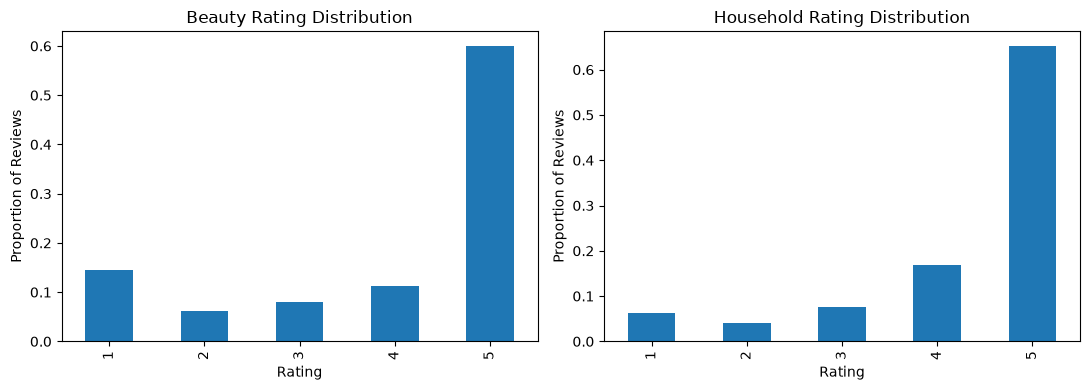

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Beauty Plot
beauty_reviews["rating"].value_counts(normalize=True).sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Beauty Rating Distribution")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Proportion of Reviews")

# Household Plot
household_reviews["rating"].value_counts(normalize=True).sort_index().plot(kind="bar", ax=axes[1])
axes[1].set_title("Household Rating Distribution")
axes[1].set_xlabel("Rating")
axes[1].set_ylabel("Proportion of Reviews")

plt.tight_layout()
plt.show()

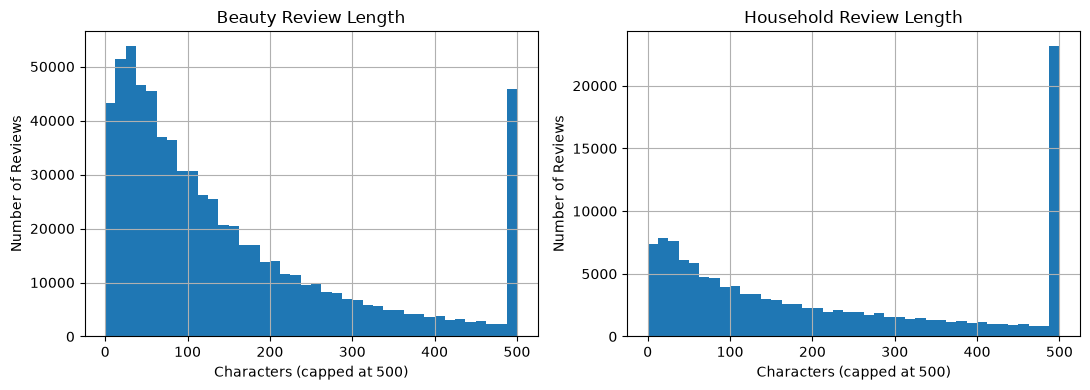

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Beauty plot
beauty_reviews["review_length"].clip(upper=500).hist(bins=40, ax=axes[0])
axes[0].set_title("Beauty Review Length")
axes[0].set_xlabel("Characters (capped at 500)")
axes[0].set_ylabel("Number of Reviews")

# Household plot
household_reviews["review_length"].clip(upper=500).hist(bins=40, ax=axes[1])
axes[1].set_title("Household Review Length")
axes[1].set_xlabel("Characters (capped at 500)")
axes[1].set_ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

### Examine Product Metadata

In [ ]:
print("Beauty Metadata Inspection: ")
print("Unique products:", beauty_meta["parent_asin"].nunique())
print("Unique stores:", beauty_meta["store"].nunique())

Beauty Metadata Inspection: 
Unique products: 112590
Unique stores: 30765


In [ ]:
print("Health and Household Metadata Inspection: ")
print("Unique products:", household_meta["parent_asin"].nunique())
print("Unique stores:", household_meta["store"].nunique())

Health and Household Metadata Inspection: 
Unique products: 797563
Unique stores: 146454


In [ ]:
# Inspect what Product Types are available within Health and Household: 
household_meta["categories"].explode().value_counts().head(20)

categories
Health & Household                     786642
Health Care                            186096
Household Supplies                     174706
Vitamins, Minerals & Supplements       121690
Medical Supplies & Equipment            95790
Alternative Medicine                    52748
Paper & Plastic                         46955
Over-the-Counter Medication             46513
Vision                                  43793
Braces, Splints & Supports              42713
Stationery & Gift Wrapping Supplies     39535
Cleaning Tools                          37134
Gift Wrapping Supplies                  36524
Aromatherapy                            36222
Oral Care                               35220
Diet & Sports Nutrition                 32662
Mobility & Daily Living Aids            31753
Wellness & Relaxation                   29102
Massage Tools & Equipment               28399
Reading Glasses                         28095
Name: count, dtype: int64

### Key Findings
* The Beauty Category has more negative reviews than the Health and Household Sample
    * specifically 145,114 negative reviews, which is substantial material for clustering
* 72% of Beauty Reviews exceed 50 characters long
* Five Star Reviews dominate which may pose a challenge in sentiment classification
    * Metrics such as Precision and Recall should be used alongside other metrics 
* Neither Category contains any missing values 
* The Beauty Category contains about ~7k duplicates, which will have to be addressed during preprocessing (in the next notebook)
* Limitations: The Household and Health Category data was only partially loaded due to it's large file size

In [ ]:
# Save the datasets for future use

beauty_reviews.to_pickle("beauty_reviews.pkl")
beauty_meta.to_pickle("beauty_meta.pkl")

NameError: name 'beauty_reviews' is not defined